# 编程练习 1：线性回归

## 介绍

在本次练习中，你将实现线性回归并观察其在数据上的表现。

本次作业所需的所有信息都包含在此笔记本中，你将实现的所有代码也将在此笔记本中完成。作业可以直接从此笔记本提交到的评分系统（下面包含代码和说明）。

在开始练习之前，我们需要导入本次编程练习所需的所有库。在整个课程中，我们将使用 [`numpy`](http://www.numpy.org/) 进行所有数组和矩阵操作，并使用 [`matplotlib`](https://matplotlib.org/) 进行绘图。


In [1]:
# 用于操作目录路径
import os
import sys
sys.path.append('.')
# Python 的科学计算和向量计算库
import numpy as np

# 绘图库
from matplotlib import pyplot
import matplotlib
matplotlib.rcParams['font.sans-serif'] = ['SimHei']  # 或 ['Microsoft YaHei']
matplotlib.rcParams['axes.unicode_minus'] = False    # 正确显示负号

# 为本次练习编写的库，提供作业提交和其他功能
import utils 

# 定义用于本次练习的提交/评分对象
grader = utils.Grader()

# 告诉 matplotlib 将图表嵌入到笔记本中
%matplotlib inline

## 提交和评分

完成作业的每一部分后，请务必将你的解决方案提交给评分系统。

对于本次编程练习，你只需要完成练习的第一部分，即实现单变量线性回归。练习的第二部分是可选的，涵盖了多变量线性回归。以下是本次练习每部分的评分细则。

**必做练习**

| 部分 | 内容                                           | 提交的函数                     | 分数 
|------|:-                                             |:-                              | :-:    
| 1    | [热身练习](#section1)                         | [`warmUpExercise`](#warmUpExercise)    |  20    
| 2    | [单变量的代价计算](#section2)                 | [`computeCost`](#computeCost)         |  20    
| 3    | [单变量的梯度下降](#section3)                 | [`gradientDescent`](#gradientDescent) |  20    
| 4    | [特征归一化](#section4)                              | [`featureNormalize`](#featureNormalize) | 20      |
| 5    | [多变量的代价计算](#section5)                        | [`computeCostMulti`](#computeCostMulti) | 20      |
| 6    | [多变量的梯度下降](#section5)                        | [`gradientDescentMulti`](#gradientDescentMulti) |20      |
| 7    | [正规方程](#section7)                                | [`normalEqn`](#normalEqn)        | 20      |
|      | 总分                                          |                                | 140    
你可以多次提交你的解决方案，我们将只考虑最高分。

<div class="alert alert-block alert-warning">
在本笔记本的每个部分末尾，我们都有一个代码单元格，用于将当前部分的解决方案提交给评分系统。执行该单元格以查看你当前的得分。为了确保你的所有工作被正确提交，你必须至少执行这些单元格一次。每次更新提交的函数时，也必须重新执行这些单元格。
</div>


## 调试

在整个练习过程中，请记住以下几点：

- Python 的数组索引从零开始，而不是从一开始（与 OCTAVE/MATLAB 相反）。 

- Python 的数组（称为 `list` 或 `tuple`）与 `numpy` 数组之间有重要区别。你应该在所有计算中使用 `numpy` 数组。向量/矩阵操作仅适用于 `numpy` 数组。Python 列表不支持向量操作（需要使用 for 循环）。

- 如果在运行时看到许多错误，请检查你的矩阵操作，确保你正在对维度兼容的矩阵进行加法和乘法操作。使用 `shape` 属性打印 `numpy` 数组的维度将有助于你调试。

- 默认情况下，`numpy` 将数学运算符解释为元素级运算符。如果你想进行矩阵乘法，需要使用 `numpy` 的 `dot` 函数。例如，如果 `A` 和 `B` 是两个 `numpy` 矩阵，那么矩阵运算 AB 是 `np.dot(A, B)`。注意，对于二维矩阵或向量（一维），这也等价于 `A@B`（需要 Python >= 3.5）。

<a id="section1"></a>
## 1 简单的 python 和 `numpy` 函数

本次作业的第一部分将让你练习 python 和 `numpy` 的语法以及作业提交流程。在下一个单元格中，你将找到一个 `python` 函数的框架。通过填写以下代码将其修改为返回一个 5 x 5 的单位矩阵：



In [2]:
def warmUpExercise():
    """
    Python 中的示例函数，用于计算单位矩阵。
    
    Returns
    -------
    A : array_like
        5x5 的单位矩阵。
    
    Instructions
    ------------
    返回 5x5 的单位矩阵。
    """    
    # ======== 在此处编写代码 ======
    A = np.eye(5)   # 修改此行
    
    # ==============================
    return A

前一个单元格仅定义了函数 `warmUpExercise`。我们现在可以通过执行以下单元格来运行它以查看其输出。你应该会看到类似于以下的输出：

```python
array([[ 1.,  0.,  0.,  0.,  0.],
       [ 0.,  1.,  0.,  0.,  0.],
       [ 0.,  0.,  1.,  0.,  0.],
       [ 0.,  0.,  0.,  1.,  0.],
       [ 0.,  0.,  0.,  0.,  1.]])
```

In [3]:
warmUpExercise()

array([[1., 0., 0., 0., 0.],
       [0., 1., 0., 0., 0.],
       [0., 0., 1., 0., 0.],
       [0., 0., 0., 1., 0.],
       [0., 0., 0., 0., 1.]])

### 1.1 提交解决方案

完成练习的某一部分后，你可以通过首先将你修改的函数添加到 `grader` 对象中，然后通过grader.grade()提交你的答案。

你可以多次提交你的解决方案，我们只会考虑最高分。

执行下一个单元格以对你在本次练习第一部分中的解决方案进行评分。

*你现在应该提交你的解决方案。*

In [4]:
# 将所有已实现的函数添加到 grader 对象中
grader[1] = warmUpExercise

# 本地评分
grader.grade()


本地评分结果

                                  Part Name | Score    | Result
                                  --------- | -------- | --------
                           Warm up exercise | 20       | 通过
          Computing Cost (for one variable) | 0        | 未通过
        Gradient Descent (for one variable) | 0        | 未通过
                      Feature Normalization | 0        | 未通过
    Computing Cost (for multiple variables) | 0        | 未通过
  Gradient Descent (for multiple variables) | 0        | 未通过
                           Normal Equations | 0        | 未通过

总分: 20 / 140


# 2 单变量线性回归

现在，你将实现单变量线性回归来预测食品卡车的利润。假设你是一家餐厅连锁店的 CEO，正在考虑在不同城市开设新店。该连锁店已经在多个城市拥有卡车，并且你拥有这些城市的人口和利润数据。你希望使用这些数据来帮助你选择下一个扩展的城市。

文件 `Data/ex1data1.txt` 包含了我们线性回归问题的数据集。第一列是城市的人口（以 10,000 为单位），第二列是该城市食品卡车的利润（以 $10,000 为单位）。利润的负值表示亏损。

我们为你提供了加载此数据所需的代码。数据集从数据文件中加载到变量 `x` 和 `y` 中：

In [5]:
# 读取逗号分隔的数据
data = np.loadtxt(os.path.join('Data', 'ex1data1.txt'), delimiter=',')
X, y = data[:, 0], data[:, 1]

m = y.size  # 训练样本的数量

### 2.1 绘制数据

在开始任何任务之前，通常通过可视化数据来理解数据是很有用的。对于这个数据集，由于它只有两个属性（利润和人口）可以绘制，因此可以使用散点图来可视化数据。你在现实生活中遇到的许多其他问题是多维的，无法在二维图上绘制。有许多 Python 的绘图库（请参阅这篇[博客文章](https://blog.modeanalytics.com/python-data-visualization-libraries/)以了解最流行的库的总结）。

在本课程中，我们将专门使用 `matplotlib` 进行所有绘图。`matplotlib` 是 Python 中最流行的科学绘图库之一，拥有广泛的工具和功能来制作精美的图表。`pyplot` 是 `matplotlib` 中的一个模块，它提供了一个简化的接口，用于完成 `matplotlib` 最常见的绘图任务，模仿 MATLAB 的绘图接口。

<div class="alert alert-block alert-warning">
你可能已经注意到，我们在本次练习的开头使用命令 `from matplotlib import pyplot` 导入了 `pyplot` 模块。这种方式相对不常见，如果你查看其他地方的 Python 代码或 `matplotlib` 教程，你会发现该模块通常被命名为 `plt`。这是通过使用导入命令 `import matplotlib.pyplot as plt` 进行模块重命名实现的。在本课程练习中，我们不会使用 `pyplot` 模块的简称，但你应该了解这种与常规的偏离。
</div>

在接下来的部分中，你的第一个任务是完成下面的 `plotData` 函数。修改该函数并填写以下代码：

```python
    pyplot.plot(x, y, 'ro', ms=10, mec='k')
    pyplot.ylabel('Profit in $10,000')
    pyplot.xlabel('Population of City in 10,000s')
```

In [6]:
def plotData(x, y):
    """
    绘制数据点 x 和 y 到一个新图中。绘制数据点并为图的坐标轴设置人口和利润的标签。
    
    参数
    ----------
    x : array_like
        x 轴的数据点值。

    y : array_like
        y 轴的数据点值。注意 x 和 y 应该具有相同的大小。
    
    说明
    ------------
    使用 "figure" 和 "plot" 函数将训练数据绘制到图中。使用 "xlabel" 和 "ylabel" 函数设置坐标轴标签。
    假设人口和收入数据已作为 x 和 y 参数传递给此函数。
    
    提示
    ----
    你可以使用 'ro' 选项与 plot 一起使用，以使标记显示为红色圆圈。此外，你可以通过使用 plot(..., 'ro', ms=10) 来使标记更大，其中 `ms` 指的是标记大小。
    你还可以使用 `mec` 属性设置标记边缘颜色。
    """
    fig = pyplot.figure()  # 打开一个新图
    
    # ====================== 在此处填写你的代码 ======================= 
    pyplot.plot(x, y, 'ro', ms=10, mec='k')
    pyplot.xlabel('Population of City in 10,000s')
    pyplot.ylabel('Profit in $10,000')

    # =============================================================


现在运行定义的函数并使用加载的数据来可视化数据。最终结果应如下图所示：

![](Figures/dataset1.png)

执行下一个单元格以可视化数据。

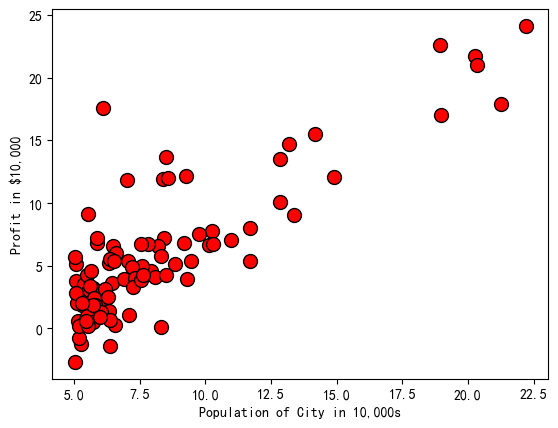

In [7]:
plotData(X, y)

要快速了解 `matplotlib` 的 plot 函数以及可以为其提供的参数，
为了将标记设置为红色圆圈，我们在 `plot` 函数中使用了选项 `'or'`。

<a id="section2"></a>
### 2.2 梯度下降

在这一部分中，你将使用梯度下降来拟合线性回归参数 $\theta$ 到我们的数据集。

#### 2.2.1 更新公式

线性回归的目标是最小化代价函数

$$ J(\theta) = \frac{1}{2m} \sum_{i=1}^m \left( h_{\theta}(x^{(i)}) - y^{(i)}\right)^2$$

其中假设函数 $h_\theta(x)$ 由线性模型给出
$$ h_\theta(x) = \theta^Tx = \theta_0 + \theta_1 x_1$$

回顾一下，模型的参数是 $\theta_j$ 值。这些是你将调整以最小化代价 $J(\theta)$ 的值。实现这一目标的一种方法是使用批量梯度下降算法。在批量梯度下降中，每次迭代执行以下更新：

$$ \theta_j = \theta_j - \alpha \frac{1}{m} \sum_{i=1}^m \left( h_\theta(x^{(i)}) - y^{(i)}\right)x_j^{(i)} \qquad \text{同时更新 } \theta_j \text{ 对于所有 } j$$

通过梯度下降的每一步，你的参数 $\theta_j$ 会更接近能够实现最低代价 $J(\theta)$ 的最优值。

<div class="alert alert-block alert-warning">
**实现注意事项：** 我们在 Python 的 `numpy` 中将每个样本存储为 $X$ 矩阵中的一行。为了考虑截距项 ($\theta_0$)，我们在 $X$ 中添加了一个额外的第一列，并将其设置为全为 1。这使我们可以将 $\theta_0$ 简单地视为另一个“特征”。
</div>


#### 2.2.2 实现

我们已经为线性回归设置了数据。在下面的单元格中，我们为数据添加了另一个维度，以适应 $\theta_0$ 截距项。不要多次执行此单元格。


In [8]:
# 向 X 添加一列全为 1 的列。numpy 函数 stack 用于沿给定轴连接数组。
# 第一个轴（axis=0）指的是行（训练样本）
# 第二个轴（axis=1）指的是列（特征）。
X = np.stack([np.ones(m), X], axis=1)

<a id="section2"></a>
#### 2.2.3 计算代价 $J(\theta)$

当你执行梯度下降以最小化代价函数 $J(\theta)$ 时，通过计算代价来监控收敛情况是很有帮助的。在本节中，你将实现一个函数来计算 $J(\theta)$，以便检查梯度下降实现的收敛性。

你的下一个任务是完成函数 `computeCost` 的代码，该函数计算 $J(\theta)$。在执行此操作时，请记住变量 $X$ 和 $y$ 不是标量值。$X$ 是一个矩阵，其行表示训练集中的示例，而 $y$ 是一个向量，其每个元素表示 $X$ 中给定行的值。
<a id="computeCost"></a>

In [9]:
def computeCost(X, y, theta):
    """
    计算线性回归的代价函数。使用 theta 作为参数来拟合 X 和 y 中的数据点。
    
    参数
    ----------
    X : array_like
        输入数据集，形状为 (m x n+1)，其中 m 是样本数量，n 是特征数量。
        我们假设特征中已经附加了一列全为 1 的向量，因此有 n+1 列。
    
    y : array_like
        函数在每个数据点的值。是一个形状为 (m, ) 的向量。
    
    theta : array_like
        回归函数的参数。是一个形状为 (n+1, ) 的向量。
    
    返回值
    -------
    J : float
        回归代价函数的值。
    
    说明
    ------------
    计算 theta 的特定选择的代价。
    你需要将 J 设置为代价值。
    """
    
    # 初始化一些有用的值
    m = y.size  # 样本数量
    
    # 你需要正确返回以下变量
    J = 0
    
    # ====================== 在此处填写代码 =====================
    h = np.dot(X, theta)
    J = (1/(2 * m)) * np.sum(np.square(h - y))
    
    
    # ===========================================================
    return J


完成函数后，下一步将使用两种不同的 $\theta$ 初始化运行 `computeCost` 两次。你将看到屏幕上打印的代价。

In [10]:
J = computeCost(X, y, theta=np.array([0.0, 0.0]))
print('With theta = [0, 0] \nCost computed = %.2f' % J)
print('Expected cost value (approximately) 32.07\n')

# 进一步测试代价函数
J = computeCost(X, y, theta=np.array([-1, 2]))
print('With theta = [-1, 2]\nCost computed = %.2f' % J)
print('Expected cost value (approximately) 54.24')

With theta = [0, 0] 
Cost computed = 32.07
Expected cost value (approximately) 32.07

With theta = [-1, 2]
Cost computed = 54.24
Expected cost value (approximately) 54.24


*你现在应该通过执行以下单元格提交你的解决方案。*

In [11]:
grader[2] = computeCost
grader.grade()


本地评分结果

                                  Part Name | Score    | Result
                                  --------- | -------- | --------
                           Warm up exercise | 20       | 通过
          Computing Cost (for one variable) | 20       | 通过
        Gradient Descent (for one variable) | 0        | 未通过
                      Feature Normalization | 0        | 未通过
    Computing Cost (for multiple variables) | 0        | 未通过
  Gradient Descent (for multiple variables) | 0        | 未通过
                           Normal Equations | 0        | 未通过

总分: 40 / 140


<a id="section3"></a>
#### 2.2.4 梯度下降

接下来，你将完成一个实现梯度下降的函数。
循环结构已经为你编写好，你只需在每次迭代中提供对 $\theta$ 的更新。

在编程时，请确保你理解你试图优化的内容以及正在更新的内容。请记住，代价函数 $J(\theta)$ 是由向量 $\theta$ 参数化的，而不是由 $X$ 和 $y$ 参数化的。也就是说，我们通过改变向量 $\theta$ 的值来最小化 $J(\theta)$ 的值，而不是通过改变 $X$ 或 $y$ 的值。[如果不确定，请参考本笔记本中的公式](#section2) 和视频讲座。验证梯度下降是否正确工作的一个好方法是查看 $J(\theta)$ 的值，并检查它是否随着每一步骤而减少。

函数 `gradientDescent` 的起始代码在每次迭代中调用 `computeCost` 并将代价保存到一个 `python` 列表中。如果你正确实现了梯度下降和 `computeCost`，那么 $J(\theta)$ 的值永远不会增加，并且应该在算法结束时收敛到一个稳定值。

<div class="alert alert-box alert-warning">
**`numpy` 中的向量和矩阵** - 重要的实现注意事项

在 `numpy` 中，向量是一维数组，例如 `np.array([1, 2, 3])` 是一个向量。矩阵是二维数组，例如 `np.array([[1, 2, 3], [4, 5, 6]])` 是一个矩阵。然而，以下内容仍然被认为是矩阵 `np.array([[1, 2, 3]])`，因为它有两个维度，即使它的形状是 1x3（看起来像一个向量）。

鉴于上述内容，我们将用于所有矩阵/向量乘法的函数 `np.dot` 具有以下属性：
- 它总是对向量执行内积。如果 `x=np.array([1, 2, 3])`，那么 `np.dot(x, x)` 是一个标量。
- 对于矩阵-向量乘法，如果 $X$ 是一个 $m\times n$ 矩阵，$y$ 是一个长度为 $m$ 的向量，那么操作 `np.dot(y, X)` 将 $y$ 视为一个 $1 \times m$ 矩阵。另一方面，如果 $y$ 是一个长度为 $n$ 的向量，那么操作 `np.dot(X, y)` 将 $y$ 视为一个 $n \times 1$ 矩阵。
- 可以使用 `y[None]` 或 `[y[np.newaxis]` 将向量提升为矩阵。也就是说，如果 `y = np.array([1, 2, 3])` 是一个大小为 3 的向量，那么 `y[None, :]` 是一个形状为 $1 \times 3$ 的矩阵。我们可以使用 `y[:, None]` 来获得一个形状为 $3 \times 1$ 的矩阵。
<div>
<a id="gradientDescent"></a>

In [12]:
def gradientDescent(X, y, theta, alpha, num_iters):
    """
    执行梯度下降以学习 `theta`。通过学习率 `alpha` 进行 `num_iters` 次梯度更新来更新 theta。
    
    参数
    ----------
    X : array_like
        输入数据集，形状为 (m x n+1)。
    
    y : array_like
        给定特征的值。形状为 (m, ) 的向量。
    
    theta : array_like
        线性回归参数的初始值。
        形状为 (n+1, ) 的向量。
    
    alpha : float
        学习率。
    
    num_iters : int
        梯度下降的迭代次数。
    
    返回值
    -------
    theta : array_like
        学到的线性回归参数。形状为 (n+1, ) 的向量。
    
    J_history : list
        一个 Python 列表，用于保存每次迭代后的代价函数值。
    
    说明
    ------------
    对参数向量 theta 执行一次梯度更新。

    在调试时，可以在此处打印出代价函数 (computeCost) 和梯度的值。
    """
    # 初始化一些有用的值
    m = y.shape[0]  # 训练样本的数量
    
    # 创建 theta 的副本，以避免更改原始数组，因为 numpy 数组是通过引用传递给函数的
    theta = theta.copy()
    
    J_history = [] # 使用一个 Python 列表来保存每次迭代的代价
    
    for i in range(num_iters):
        # ==================== 在此处填写你的代码 =================================
        theta = theta - alpha / m * (np.dot(X, theta) - y).dot(X)
        

        # =====================================================================
        
        # 在每次迭代中保存代价 J
        J_history.append(computeCost(X, y, theta))
    
    return theta, J_history


完成后调用实现的 `gradientDescent` 函数并打印计算出的 $\theta$。我们将 $\theta$ 参数初始化为 0，学习率 $\alpha$ 初始化为 0.01。执行以下单元格以检查你的代码。

In [13]:
# 初始化拟合参数
theta = np.zeros(2)

# 一些梯度下降的设置
iterations = 1500  # 迭代次数
alpha = 0.01  # 学习率

theta, J_history = gradientDescent(X, y, theta, alpha, iterations)
print('Theta found by gradient descent: {:.4f}, {:.4f}'.format(*theta))
print('Expected theta values (approximately): [-3.6303, 1.1664]')

Theta found by gradient descent: -3.6303, 1.1664
Expected theta values (approximately): [-3.6303, 1.1664]


我们将使用你的最终参数绘制线性拟合。结果应如下图所示。

![](Figures/regression_result.png)

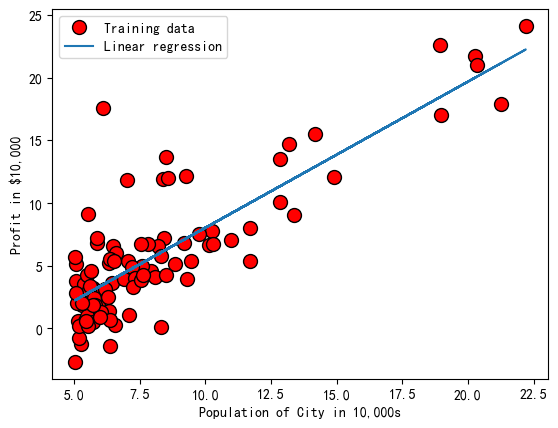

In [14]:
# 绘制线性拟合
plotData(X[:, 1], y)
pyplot.plot(X[:, 1], np.dot(X, theta), '-')
pyplot.legend(['Training data', 'Linear regression']);

你的最终 $\theta$ 值也将用于预测在人口为 35,000 和 70,000 的地区的利润。

<div class="alert alert-block alert-success">
注意以下代码行使用矩阵乘法，而不是显式求和或循环来计算预测值。这是 `numpy` 中代码向量化的一个示例。
</div>

<div class="alert alert-block alert-success">
注意，`numpy` 函数 `dot` 的第一个参数是一个 Python 列表。`numpy` 可以在显式提供为 `numpy` 函数的参数时，内部将**有效的** Python 列表转换为 numpy 数组。
</div>


In [15]:
# 预测人口规模为 35,000 和 70,000 的值
predict1 = np.dot([1, 3.5], theta)
print('For population = 35,000, we predict a profit of {:.2f}\n'.format(predict1*10000))

predict2 = np.dot([1, 7], theta)
print('For population = 70,000, we predict a profit of {:.2f}\n'.format(predict2*10000))

For population = 35,000, we predict a profit of 4519.77

For population = 70,000, we predict a profit of 45342.45



*你现在应该通过执行下一个单元格提交你的解决方案。*

In [16]:
grader[3] = gradientDescent
grader.grade()


本地评分结果

                                  Part Name | Score    | Result
                                  --------- | -------- | --------
                           Warm up exercise | 20       | 通过
          Computing Cost (for one variable) | 20       | 通过
        Gradient Descent (for one variable) | 20       | 通过
                      Feature Normalization | 0        | 未通过
    Computing Cost (for multiple variables) | 0        | 未通过
  Gradient Descent (for multiple variables) | 0        | 未通过
                           Normal Equations | 0        | 未通过

总分: 60 / 140


### 2.4 可视化 $J(\theta)$

为了更好地理解代价函数 $J(\theta)$，你现在将绘制 $\theta_0$ 和 $\theta_1$ 值的二维网格上的代价图。你不需要为此部分编写任何新代码，但你应该理解你已经编写的代码是如何创建这些图像的。

在下一个单元格中，代码设置为使用你编写的 `computeCost` 函数计算网格值上的 $J(\theta)$。执行以下单元格后，你将获得一个 $J(\theta)$ 值的二维数组。然后，这些值将用于使用 matplotlib 的 `plot_surface` 和 `contourf` 函数生成 $J(\theta)$ 的表面图和等高线图。图像应类似于以下内容：

![](Figures/cost_function.png)

这些图的目的是向你展示 $J(\theta)$ 如何随着 $\theta_0$ 和 $\theta_1$ 的变化而变化。代价函数 $J(\theta)$ 是碗状的，并且具有全局最小值。（在等高线图中比在 3D 表面图中更容易看到这一点）。这个最小值是 $\theta_0$ 和 $\theta_1$ 的最优点，梯度下降的每一步都会更接近这一点。

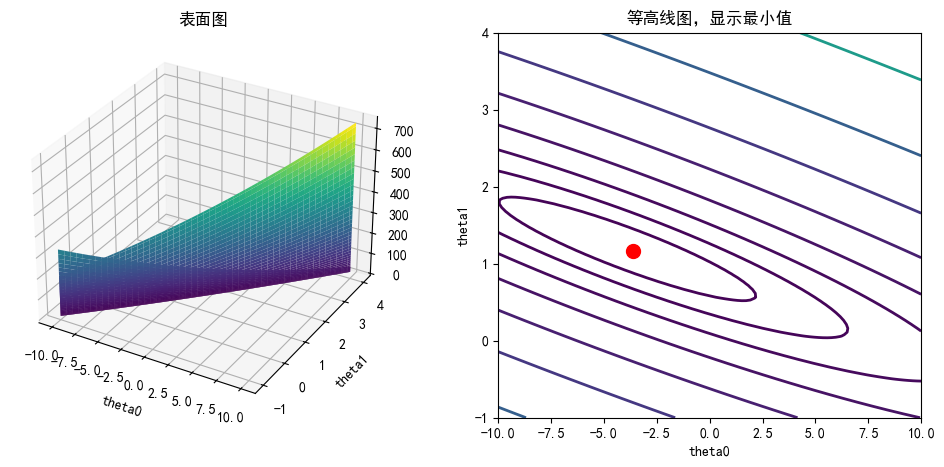

In [17]:
# 网格范围，我们将在其上计算 J
theta0_vals = np.linspace(-10, 10, 100)
theta1_vals = np.linspace(-1, 4, 100)

# 将 J_vals 初始化为一个全为 0 的矩阵
J_vals = np.zeros((theta0_vals.shape[0], theta1_vals.shape[0]))

# 填充 J_vals
for i, theta0 in enumerate(theta0_vals):
    for j, theta1 in enumerate(theta1_vals):
        J_vals[i, j] = computeCost(X, y, [theta0, theta1])
        
# 由于 meshgrids 在 surf 命令中的工作方式，我们需要在调用 surf 之前转置 J_vals，否则轴会被翻转
J_vals = J_vals.T

# 表面图
fig = pyplot.figure(figsize=(12, 5))
ax = fig.add_subplot(121, projection='3d')
ax.plot_surface(theta0_vals, theta1_vals, J_vals, cmap='viridis')
pyplot.xlabel('theta0')
pyplot.ylabel('theta1')
pyplot.title('表面图')

# 等高线图
# 将 J_vals 绘制为 15 条等高线，等高线在 0.01 和 100 之间以对数间隔分布
ax = pyplot.subplot(122)
pyplot.contour(theta0_vals, theta1_vals, J_vals, linewidths=2, cmap='viridis', levels=np.logspace(-2, 3, 20))
pyplot.xlabel('theta0')
pyplot.ylabel('theta1')
pyplot.plot(theta[0], theta[1], 'ro', ms=10, lw=2)
pyplot.title('等高线图，显示最小值')
pass



## 3 多变量线性回归

在本部分中，你将实现多变量线性回归以预测房屋价格。假设你正在出售你的房屋，并且想知道一个合理的市场价格是多少。一种方法是首先收集最近售出的房屋信息，并建立一个房价模型。

文件 `Data/ex1data2.txt` 包含了波特兰市的房价训练集。第一列是房屋的大小（以平方英尺为单位），第二列是卧室的数量，第三列是房屋的价格。

<a id="section4"></a>
### 3.1 特征归一化

我们首先加载并显示该数据集中的一些值。通过查看这些值，请注意房屋大小大约是卧室数量的 1000 倍。当特征的数量级差异较大时，首先执行特征缩放可以使梯度下降收敛得更快。


In [18]:
# 加载数据
data = np.loadtxt(os.path.join('Data', 'ex1data2.txt'), delimiter=',')
X = data[:, :2]
y = data[:, 2]
m = y.size

# 打印一些数据点
print('{:>8s}{:>8s}{:>10s}'.format('X[:,0]', 'X[:, 1]', 'y'))
print('-'*26)
for i in range(10):
    print('{:8.0f}{:8.0f}{:10.0f}'.format(X[i, 0], X[i, 1], y[i]))

  X[:,0] X[:, 1]         y
--------------------------
    2104       3    399900
    1600       3    329900
    2400       3    369000
    1416       2    232000
    3000       4    539900
    1985       4    299900
    1534       3    314900
    1427       3    198999
    1380       3    212000
    1494       3    242500


你的任务是完成 `featureNormalize` 函数中的代码：
- 从数据集中减去每个特征的均值。
- 在减去均值后，还需要将特征值除以其各自的“标准差”进行缩放。

标准差是一种衡量特定特征值范围内变化程度的方法（大多数数据点将位于均值的 ±2 个标准差范围内）；这是取值范围（最大值-最小值）的替代方法。在 `numpy` 中，你可以使用 `std` 函数来计算标准差。

例如，数量 `X[:, 0]` 包含训练集中所有的 $x_1$（房屋大小）值，因此 `np.std(X[:, 0])` 计算房屋大小的标准差。
在调用 `featureNormalize` 函数时，与 $x_0 = 1$ 对应的额外列 1 尚未添加到 $X$ 中。

你需要对所有特征执行此操作，并且你的代码应适用于所有大小的数据集（任意数量的特征/示例）。请注意，矩阵 $X$ 的每一列对应一个特征。

<div class="alert alert-block alert-warning">
**实现注意事项：** 在归一化特征时，存储用于归一化的值（均值和标准差）非常重要。在从模型中学习到参数后，我们通常希望预测之前未见过的房屋价格。给定一个新的 x 值（客厅面积和卧室数量），我们必须首先使用从训练集中先前计算的均值和标准差对 x 进行归一化。
</div>
<a id="featureNormalize"></a>


In [19]:
def  featureNormalize(X):
    """
    对 X 中的特征进行归一化。返回一个归一化后的版本，其中每个特征的均值为 0，标准差为 1。
    这是在使用学习算法时一个常见的预处理步骤。
    
    参数
    ----------
    X : array_like
        数据集，形状为 (m x n)。
    
    返回值
    -------
    X_norm : array_like
        归一化后的数据集，形状为 (m x n)。
    
    说明
    ------------
    首先，对于每个特征维度，计算该特征的均值，并从数据集中减去该均值，将均值存储在 mu 中。
    接下来，计算每个特征的标准差，并将每个特征除以其标准差，将标准差存储在 sigma 中。
    
    注意，X 是一个矩阵，其中每列是一个特征，每行是一个样本。你需要分别对每个特征进行归一化。
    
    提示
    ----
    你可能会发现 'np.mean' 和 'np.std' 函数很有用。
    """
    # 你需要正确设置这些值
    X_norm = X.copy()
    mu = np.zeros(X.shape[1])
    sigma = np.zeros(X.shape[1])

    # =========================== 在此处填写代码 =====================
    mu = np.mean(X, axis = 0)
    sigma = np.std(X, axis = 0)
    X_norm = (X - mu) / sigma
    
    
    # ================================================================
    return X_norm, mu, sigma


执行下一个单元格以运行已实现的 `featureNormalize` 函数。

In [20]:
# 在加载的数据上调用 featureNormalize
X_norm, mu, sigma = featureNormalize(X)

print('Computed mean:', mu)
print('Computed standard deviation:', sigma)

Computed mean: [2000.68085106    3.17021277]
Computed standard deviation: [7.86202619e+02 7.52842809e-01]


*请提交你的解决方案。*

In [21]:
grader[4] = featureNormalize
grader.grade()


本地评分结果

                                  Part Name | Score    | Result
                                  --------- | -------- | --------
                           Warm up exercise | 20       | 通过
          Computing Cost (for one variable) | 20       | 通过
        Gradient Descent (for one variable) | 20       | 通过
                      Feature Normalization | 20       | 通过
    Computing Cost (for multiple variables) | 0        | 未通过
  Gradient Descent (for multiple variables) | 0        | 未通过
                           Normal Equations | 0        | 未通过

总分: 80 / 140


在测试 `featureNormalize` 函数之后，我们现在将截距项添加到 `X_norm`：

In [22]:
# 添加截距项到 X
X = np.concatenate([np.ones((m, 1)), X_norm], axis=1)

<a id="section5"></a>
### 3.2 梯度下降

之前，你已经在单变量回归问题上实现了梯度下降。现在唯一的区别是矩阵 $X$ 中多了一个特征。假设函数和批量梯度下降更新规则保持不变。

你需要完成函数 `computeCostMulti` 和 `gradientDescentMulti` 的代码，以实现多变量线性回归的代价函数和梯度下降。如果你在前一部分（单变量）中的代码已经支持多变量，你也可以在这里使用它。
确保你的代码支持任意数量的特征，并且是良好向量化的。
你可以使用 `numpy` 数组的 `shape` 属性来找出数据集中有多少特征。

<div class="alert alert-block alert-warning">
**实现注意事项：** 在多变量情况下，代价函数也可以写成以下向量化形式：

$$ J(\theta) = \frac{1}{2m}(X\theta - \vec{y})^T(X\theta - \vec{y}) $$

其中 

$$ X = \begin{pmatrix}
      - (x^{(1)})^T - \\
      - (x^{(2)})^T - \\
      \vdots \\
      - (x^{(m)})^T - \\ \\
    \end{pmatrix} \qquad \mathbf{y} = \begin{bmatrix} y^{(1)} \\ y^{(2)} \\ \vdots \\ y^{(m)} \\\end{bmatrix}$$

向量化版本在使用像 `numpy` 这样的数值计算工具时非常高效。如果你擅长矩阵运算，可以自己证明这两种形式是等价的。
</div>

<a id="computeCostMulti"></a>


In [23]:
def computeCostMulti(X, y, theta):
    """
    计算多变量线性回归的代价函数。
    使用 theta 作为参数来拟合 X 和 y 中的数据点，并计算代价。
    
    参数
    ----------
    X : array_like
        数据集，形状为 (m x n+1)。
    
    y : array_like
        一个形状为 (m, ) 的向量，表示每个数据点的值。
    
    theta : array_like
        线性回归的参数。一个形状为 (n+1, ) 的向量。
    
    返回值
    -------
    J : float
        代价函数的值。
    
    说明
    ------------
    计算 theta 的特定选择的代价。你需要将 J 设置为代价值。
    """
    # 初始化一些有用的值
    m = y.shape[0] # 训练样本的数量
    
    # 你需要正确返回以下变量
    J = 0
    
    # ======================= 在此处填写代码 ===========================
    J = 1/(2 * m) * np.sum( (np.dot(X, theta) - y) ** 2 )

    
    
    # ==================================================================
    return J


*你现在应该提交你的解决方案。*

In [24]:
grader[5] = computeCostMulti
grader.grade()


本地评分结果

                                  Part Name | Score    | Result
                                  --------- | -------- | --------
                           Warm up exercise | 20       | 通过
          Computing Cost (for one variable) | 20       | 通过
        Gradient Descent (for one variable) | 20       | 通过
                      Feature Normalization | 20       | 通过
    Computing Cost (for multiple variables) | 20       | 通过
  Gradient Descent (for multiple variables) | 0        | 未通过
                           Normal Equations | 0        | 未通过

总分: 100 / 140


<a id="gradientDescentMulti"></a>

In [25]:
def gradientDescentMulti(X, y, theta, alpha, num_iters):
    """
    执行梯度下降以学习 theta。
    通过学习率 alpha 进行 num_iters 次梯度更新来更新 theta。
        
    参数
    ----------
    X : array_like
        数据集，形状为 (m x n+1)。
    
    y : array_like
        一个形状为 (m, ) 的向量，表示每个数据点的值。
    
    theta : array_like
        线性回归的参数。一个形状为 (n+1, ) 的向量。
    
    alpha : float
        梯度下降的学习率。
    
    num_iters : int
        梯度下降的迭代次数。
    
    返回值
    -------
    theta : array_like
        学到的线性回归参数。一个形状为 (n+1, ) 的向量。
    
    J_history : list
        一个 Python 列表，用于保存每次迭代后的代价函数值。
    
    说明
    ------------
    对参数向量 theta 执行一次梯度更新。

    在调试时，可以在此处打印出代价函数 (computeCost) 和梯度的值。
    """
    # 初始化一些有用的值
    m = y.shape[0] # 训练样本的数量
    
    # 创建 theta 的副本，以避免更改原始数组，因为 numpy 数组是通过引用传递给函数的
    theta = theta.copy()
    
    J_history = []
    
    for i in range(num_iters):
        # ======================= 在此处填写代码 ==========================
        theta = theta - alpha*1 / m * (np.dot(X, theta) - y).dot(X)
        # =================================================================
        
        # 在每次迭代中保存代价 J
        J_history.append(computeCostMulti(X, y, theta))
    
    return theta, J_history


*你现在应该提交你的解决方案。*

In [26]:
grader[6] = gradientDescentMulti
grader.grade()


本地评分结果

                                  Part Name | Score    | Result
                                  --------- | -------- | --------
                           Warm up exercise | 20       | 通过
          Computing Cost (for one variable) | 20       | 通过
        Gradient Descent (for one variable) | 20       | 通过
                      Feature Normalization | 20       | 通过
    Computing Cost (for multiple variables) | 20       | 通过
  Gradient Descent (for multiple variables) | 20       | 通过
                           Normal Equations | 0        | 未通过

总分: 120 / 140


#### 3.2.1 可选（未评分）练习：选择学习率

在本部分练习中，你将尝试为数据集选择不同的学习率，并找到一个能够快速收敛的学习率。你可以通过修改以下代码并更改设置学习率的部分来调整学习率。

使用你实现的 `gradientDescentMulti` 函数，并在所选学习率下运行大约 50 次迭代。该函数还应返回 $J(\theta)$ 值的历史记录，存储在向量 $J$ 中。

在最后一次迭代后，将 $J$ 值与迭代次数绘制在图上。

如果你选择的学习率在一个合适的范围内，你的图表应类似于下图。

![](Figures/learning_rate.png)

如果你的图表看起来非常不同，尤其是如果 $J(\theta)$ 的值增加甚至发散，请调整你的学习率并重试。我们建议尝试以对数刻度的学习率 $\alpha$，每次以大约 3 倍的步长递减（例如，0.3、0.1、0.03、0.01 等）。如果这有助于你观察曲线的整体趋势，你可能还需要调整运行的迭代次数。

<div class="alert alert-block alert-warning">
**实现注意事项：** 如果你的学习率过大，$J(\theta)$ 可能会发散并“爆炸”，导致值过大而无法进行计算。在这些情况下，`numpy` 通常会返回 NaN。NaN 表示“不是一个数字”，通常由涉及 −∞ 和 +∞ 的未定义操作引起。
</div>

<div class="alert alert-block alert-warning">
**MATPLOTLIB 提示：** 为了比较不同学习率如何影响收敛，在同一图中绘制多个学习率的 $J$ 是很有帮助的。这可以通过将 `alpha` 设置为一个 Python 列表，并在该列表中的值上循环，在每次循环中调用 plot 函数来实现。使用图例来区分图中的不同线条也很有用。在线搜索 `pyplot.legend` 以获取有关在 `matplotlib` 中显示图例的帮助。
</div>

注意随着学习率的变化，收敛曲线的变化。对于较小的学习率，你会发现梯度下降需要很长时间才能收敛到最优值。相反，对于较大的学习率，梯度下降可能无法收敛，甚至可能发散！
使用你找到的最佳学习率，运行脚本直到收敛以找到 $\theta$ 的最终值。接下来，使用此 $\theta$ 值预测一个 1650 平方英尺、3 间卧室的房屋价格。稍后你将使用此值来检查你对正规方程的实现。进行此预测时，请不要忘记对特征进行归一化！


通过梯度下降计算的 theta: [340412.65957447 109447.79558639  -6578.3539709 ]
预测的 1650 平方英尺、3 间卧室房屋价格 (使用梯度下降): $293081


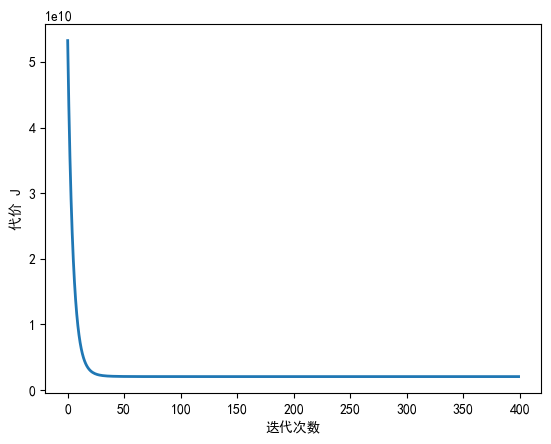

In [27]:
"""
说明
------------
我们为你提供了以下初始代码，该代码使用特定的学习率 (alpha) 运行梯度下降。

你的任务是首先确保你的函数 - `computeCost` 和 `gradientDescent` 已经可以与此初始代码一起工作，并支持多变量。

之后，尝试使用不同的 alpha 值运行梯度下降，看看哪个值能给你最佳结果。

最后，你应该完成末尾的代码，以预测一个 1650 平方英尺、3 间卧室的房屋价格。

提示
----
在预测时，请确保你执行了相同的特征归一化。
"""
# 选择一个 alpha 值 - 修改此处
alpha = 0.1
num_iters = 400

# 初始化 theta 并运行梯度下降
theta = np.zeros(3)
theta, J_history = gradientDescentMulti(X, y, theta, alpha, num_iters)

# 绘制收敛图
pyplot.plot(np.arange(len(J_history)), J_history, lw=2)
pyplot.xlabel('迭代次数')
pyplot.ylabel('代价 J')

# 显示梯度下降的结果
print('通过梯度下降计算的 theta: {:s}'.format(str(theta)))
price = 0

# 估算一个 1650 平方英尺、3 间卧室房屋的价格
# ======================= 在此处填写你的代码 ===========================
# 请记住，X 的第一列是全为 1 的。
# 因此，它不需要归一化。
X_array = [1, 1650, 3]
X_array[1:3] = (X_array[1:3] - mu) / sigma
price = np.dot(X_array, theta)


# ===================================================================

print('预测的 1650 平方英尺、3 间卧室房屋价格 (使用梯度下降): ${:.0f}'.format(price))


*你不需要为此可选（未评分）部分提交任何解决方案。*

<a id="section7"></a>
### 3.3 正规方程

在讲座视频中，你了解到线性回归的闭式解为：

$$ \theta = \left( X^T X\right)^{-1} X^T\vec{y}$$

使用此公式不需要任何特征缩放，你可以通过一次计算获得精确解：不像梯度下降那样需要“循环直到收敛”。

首先，我们将重新加载数据以确保变量未被修改。请记住，虽然你不需要对特征进行缩放，但我们仍然需要向 $X$ 矩阵添加一列全为 1 的列，以包含截距项 ($\theta_0$)。下一单元格中的代码将为你添加全为 1 的列到 X。

In [28]:
# 加载数据
data = np.loadtxt(os.path.join('Data', 'ex1data2.txt'), delimiter=',')
X = data[:, :2]
y = data[:, 2]
m = y.size
X = np.concatenate([np.ones((m, 1)), X], axis=1)

完成下面函数 `normalEqn` 的代码，使用上述公式计算 $\theta$。

<a id="normalEqn"></a>

In [29]:
def normalEqn(X, y):
    """
    使用正规方程计算线性回归的闭式解。
    
    参数
    ----------
    X : array_like
        数据集，形状为 (m x n+1)。
    
    y : array_like
        每个数据点的值。形状为 (m, ) 的向量。
    
    返回值
    -------
    theta : array_like
        估计的线性回归参数。形状为 (n+1, ) 的向量。
    
    说明
    ------------
    完成代码以计算线性回归的闭式解，并将结果存储在 theta 中。
    
    提示
    ----
    查阅函数 `np.linalg.pinv` 以计算矩阵的逆。
    """
    theta = np.zeros(X.shape[1])
    
    # ===================== 在此处填写代码 ============================
    theta = np.linalg.inv(np.dot(X.T, X)).dot(X.T).dot(y)
    
    
    # =================================================================
    return theta


*你现在应该提交你的解决方案。*

In [30]:
grader[7] = normalEqn
grader.grade()


本地评分结果

                                  Part Name | Score    | Result
                                  --------- | -------- | --------
                           Warm up exercise | 20       | 通过
          Computing Cost (for one variable) | 20       | 通过
        Gradient Descent (for one variable) | 20       | 通过
                      Feature Normalization | 20       | 通过
    Computing Cost (for multiple variables) | 20       | 通过
  Gradient Descent (for multiple variables) | 20       | 通过
                           Normal Equations | 20       | 通过

总分: 140 / 140


可选（未评分）练习：现在，一旦你使用此方法找到 $\theta$，请使用它为一个 1650 平方英尺、3 间卧室的房屋进行价格预测。你应该发现，这与使用梯度下降拟合的模型（在第 3.2.1 节中）获得的预测价格相同。


In [ ]:
# 使用正规方程计算参数
theta = normalEqn(X, y)

# 显示正规方程的结果
print('Theta computed from the normal equations: {:s}'.format(str(theta)))

# 估算一个 1650 平方英尺、3 间卧室房屋的价格
# ====================== 在此处填写你的代码 ======================
X_array = [1, 1650, 3]
price = np.dot(X_array, theta)



# ============================================================

print('Predicted price of a 1650 sq-ft, 3 br house (using normal equations): ${:.0f}'.format(price))

Theta computed from the normal equations: [89597.9095428    139.21067402 -8738.01911233]
Predicted price of a 1650 sq-ft, 3 br house (using normal equations): $293081
